In [6]:
import pandas as pd
df = pd.read_csv(r"C:\Users\kanik\AppData\Local\Packages\5319275A.WhatsAppDesktop_cv1g1gvanyjgm\LocalState\sessions\D39B0605F03F772608F93C16EB400D5A08E07147\transfers\2026-23\Mall_Customers.csv")
df.head(10) 



,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [7]:
print("shape of dataset" , df.shape)
print("Rows =" , df.shape[0])
print("column = " , df.shape[1])

shape of dataset (200, 5)
Rows = 200
column =  5


In [8]:
print(df.columns)

Index(['CustomerID', 'Gender', 'Age', 'Annual Income (k$)',
       'Spending Score (1-100)'],
      dtype='object')


In [9]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [10]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [16]:
print("Shape of Dataset:", df.shape)

print("Rows =", df.shape[0])
print("Columns =", df.shape[1])


Shape of Dataset: (200, 5)
Rows = 200
Columns = 5


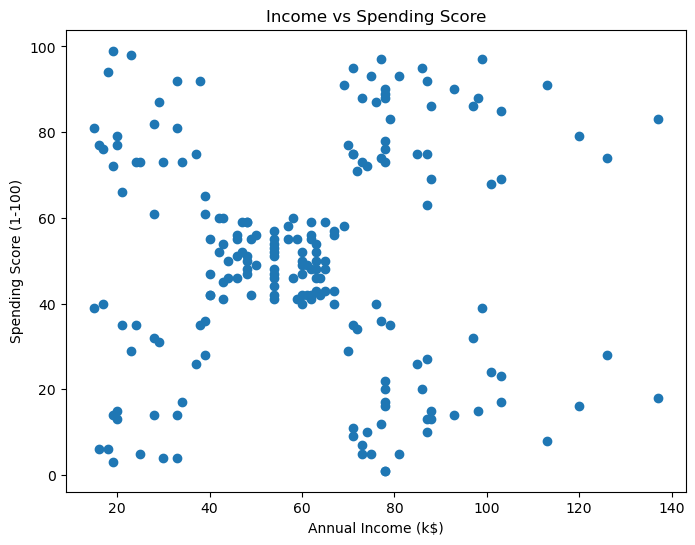

In [18]:
import matplotlib.pyplot as plt 
plt.figure(figsize=(8,6))

plt.scatter(df['Annual Income (k$)'] ,
            df['Spending Score (1-100)'])
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.title("Income vs Spending Score")

plt.show()

     

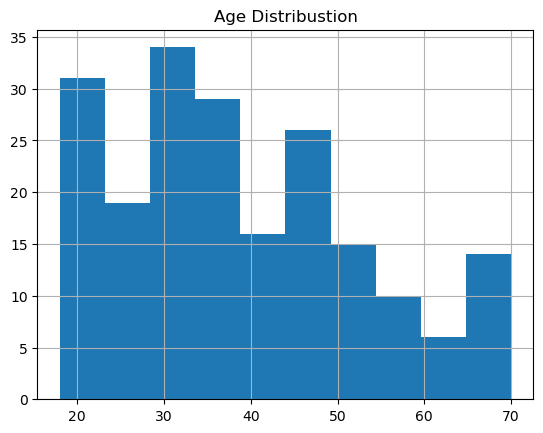

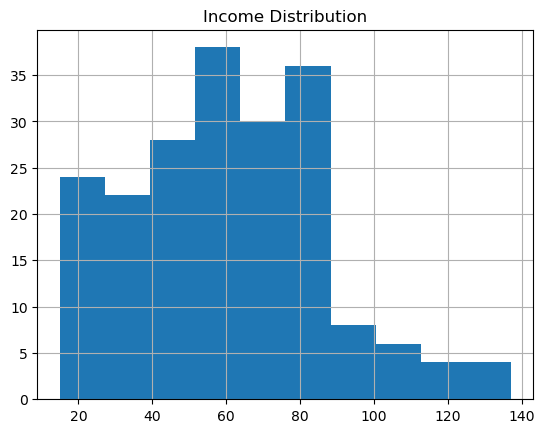

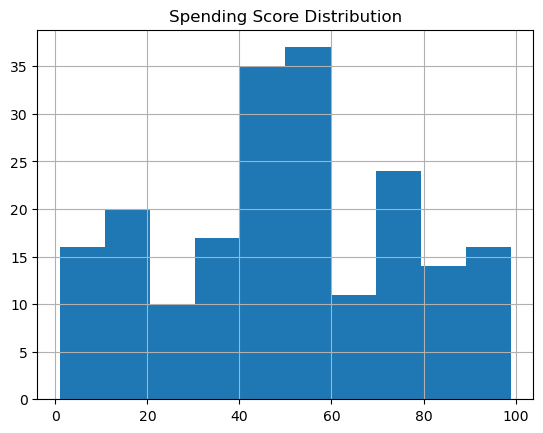

In [19]:
df['Age'].hist()
plt.title("Age Distribustion")
plt.show()

df['Annual Income (k$)'].hist()
plt.title("Income Distribution")
plt.show()

df['Spending Score (1-100)'].hist()
plt.title("Spending Score Distribution")
plt.show()


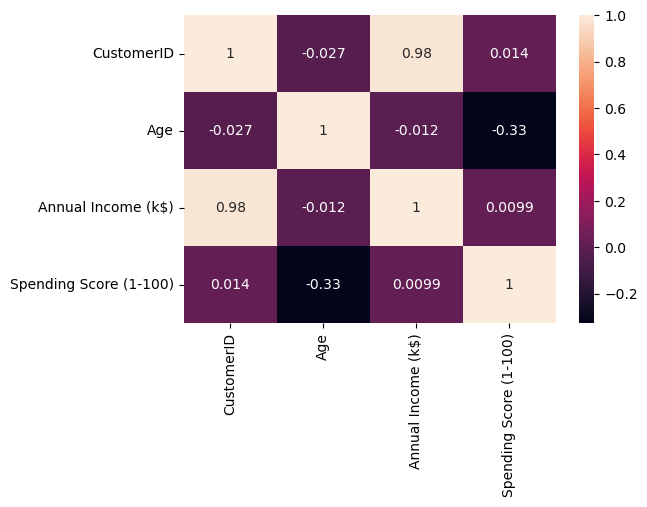

In [20]:
import seaborn as sns

plt.figure(figsize=(6,4))
sns.heatmap(df.select_dtypes(include= 'number').corr(),
            annot=True)

plt.show()
            


In [21]:
X = df[['Annual Income (k$)',
        'Spending Score (1-100)']]

X.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [23]:
from sklearn.cluster import KMeans 

wcss  = []
for i in range(1,11):
    kmeans = KMeans(
        n_clusters = i,
        random_state = 42,
        n_init = 10
    )
    kmeans.fit(X)

    wcss.append(kmeans.inertia_)
    
    

C:\Users\kanik\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\kanik\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\kanik\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\kanik\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

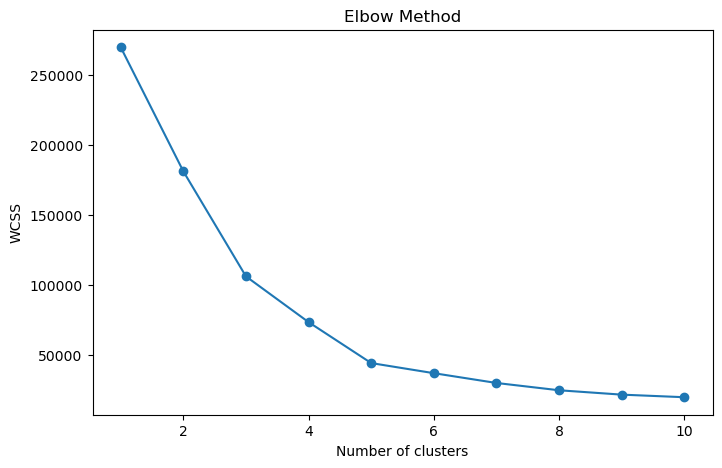

In [25]:
plt.figure(figsize=(8,5))

plt.plot(range(1,11),
         wcss,
         marker = 'o')

plt.xlabel("Number of clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")

plt.show()

In [27]:
from sklearn.cluster import KMeans 
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init = 10
)
kmeans.fit(X)

C:\Users\kanik\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


KMeans(n_clusters=5, n_init=10, random_state=42)

In [29]:
df['cluster'] = kmeans.predict(X)

print(df['cluster'])

0      4
1      2
2      4
3      2
4      4
      ..
195    1
196    3
197    1
198    3
199    1
Name: cluster, Length: 200, dtype: int32


In [30]:
df.head(10)

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,cluster
0,1,Male,19,15,39,4,4
1,2,Male,21,15,81,2,2
2,3,Female,20,16,6,4,4
3,4,Female,23,16,77,2,2
4,5,Female,31,17,40,4,4
5,6,Female,22,17,76,2,2
6,7,Female,35,18,6,4,4
7,8,Female,23,18,94,2,2
8,9,Male,64,19,3,4,4
9,10,Female,30,19,72,2,2


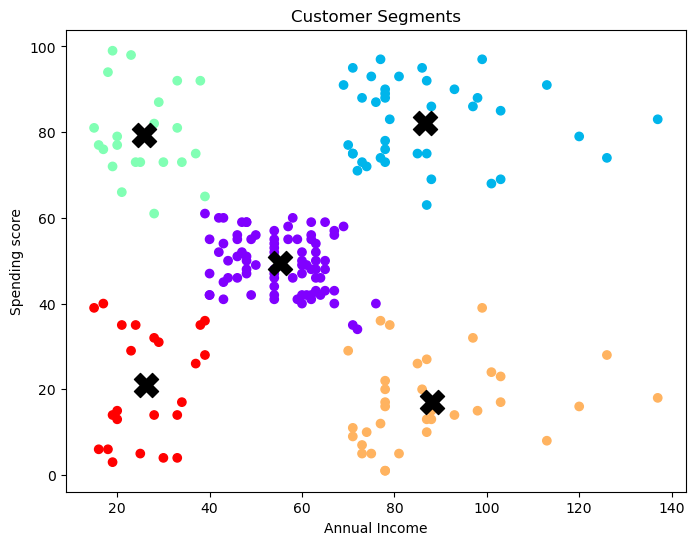

In [32]:
plt.figure(figsize=(8,6))

plt.scatter(
    X.iloc[:,0],
    X.iloc[:,1],
    c = df['Cluster'],
    cmap = 'rainbow'
)
plt.scatter(
    kmeans.cluster_centers_[:,0],
    kmeans.cluster_centers_[:,1],
    s = 300,
    c = 'black',
    marker = 'X'
)
plt.xlabel("Annual Income")
plt.ylabel("Spending score")
plt.title("Customer Segments")

plt.show()

In [33]:
print(kmeans.cluster_centers_)

[[55.2962963  49.51851852]
 [86.53846154 82.12820513]
 [25.72727273 79.36363636]
 [88.2        17.11428571]
 [26.30434783 20.91304348]]


In [37]:
centroid = pd.DataFrame(
    kmeans.cluster_centers_,
    columns=['Annual Income (k$)', 'Spending Score (1-100)']
)

print(centroid)

   Annual Income (k$)  Spending Score (1-100)
0           55.296296               49.518519
1           86.538462               82.128205
2           25.727273               79.363636
3           88.200000               17.114286
4           26.304348               20.913043


In [38]:
cluster_summary = df.groupby('Cluster')[
    ['Annual Income (k$)', 'Spending Score (1-100)']
].mean()

print(cluster_summary)

         Annual Income (k$)  Spending Score (1-100)
Cluster                                            
0                 55.296296               49.518519
1                 86.538462               82.128205
2                 25.727273               79.363636
3                 88.200000               17.114286
4                 26.304348               20.913043


In [39]:
for cluster in sorted(df['Cluster'].unique()):
    print(f"Cluster {cluster}")

Cluster 0
Cluster 1
Cluster 2
Cluster 3
Cluster 4


In [40]:
print("Total Customers =", len(df))
print("Total Clusters =", df['Cluster'].nunique())

print("\nCustomers in each Cluster:")
print(df['Cluster'].value_counts())

Total Customers = 200
Total Clusters = 5

Customers in each Cluster:
Cluster
0    81
1    39
3    35
4    23
2    22
Name: count, dtype: int64


In [41]:
cluster_summary

,Annual Income (k$),Spending Score (1-100)
Cluster,,
0,55.296296,49.518519
1,86.538462,82.128205
2,25.727273,79.363636
3,88.200000,17.114286
4,26.304348,20.913043


In [42]:
print("Advantages:")
print("1. Simple to implement")
print("2. Fast on large datasets")
print("3. Easy to interpret")

print("\nLimitations:")
print("1. Requires predefined K")
print("2. Sensitive to outliers")
print("3. Assumes spherical clusters")

Advantages:
1. Simple to implement
2. Fast on large datasets
3. Easy to interpret

Limitations:
1. Requires predefined K
2. Sensitive to outliers
3. Assumes spherical clusters
